# AAI614: Data Science & its Applications

*Notebook 7.2: Accelerating Data Science*

<a href="https://colab.research.google.com/github/harmanani/AAI614/blob/main/Week%207/Notebook7.2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Source: Data Science with Python and Dask

### Examining the Metadata of Dask Objects

You would need for this lab to downlaod the data and store on your local disk as it is arond 2GB with 42.3M Rows of Parking Ticket Data.  The data can be downloaded from [Kaggle](http://www.kaggle.com/new-york-city/nyc-parking-tickets/)

In [1]:
import dask.dataframe as dd
from dask.diagnostics import ProgressBar
from matplotlib import pyplot as plt

# dtype=str avoids Dask's dtype-inference mismatch errors on this mixed-type dataset
df = dd.read_csv(r'C:\Users\USER\Downloads\archive (1)\*2017.csv', dtype=str)
df

,Summons Number,Plate ID,Registration State,Plate Type,Issue Date,Violation Code,Vehicle Body Type,Vehicle Make,Issuing Agency,Street Code1,Street Code2,Street Code3,Vehicle Expiration Date,Violation Location,Violation Precinct,Issuer Precinct,Issuer Code,Issuer Command,Issuer Squad,Violation Time,Time First Observed,Violation County,Violation In Front Of Or Opposite,House Number,Street Name,Intersecting Street,Date First Observed,Law Section,Sub Division,Violation Legal Code,Days Parking In Effect,From Hours In Effect,To Hours In Effect,Vehicle Color,Unregistered Vehicle?,Vehicle Year,Meter Number,Feet From Curb,Violation Post Code,Violation Description,No Standing or Stopping Violation,Hydrant Violation,Double Parking Violation
npartitions=32,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string,string
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


In [2]:
missing_values = df.isnull().sum()
missing_values

Dask Series Structure:
npartitions=1
Date First Observed    int64
Violation Time           ...
Dask Name: sum, 5 expressions
Expr=(~ NotNull(frame=ArrowStringConversion(frame=FromMapProjectable(1f2fa6d)))).sum()

In [3]:
missing_count = ((missing_values / df.index.size) * 100)
missing_count

Dask Series Structure:
npartitions=1
Date First Observed    float64
Violation Time             ...
Dask Name: mul, 9 expressions
Expr=(~ NotNull(frame=ArrowStringConversion(frame=FromMapProjectable(1f2fa6d)))).sum() / Index(frame=ArrowStringConversion(frame=FromMapProjectable(1f2fa6d))).size() * 100

### Running Computations with the Compute Method

In [4]:
with ProgressBar():
    missing_count_pct = missing_count.compute()
missing_count_pct

[########################################] | 100% Completed | 67.12 s


Summons Number                         0.000000
Plate ID                               0.006739
Registration State                     0.000000
Plate Type                             0.000000
Issue Date                             0.000000
Violation Code                         0.000000
Vehicle Body Type                      0.395361
Vehicle Make                           0.676199
Issuing Agency                         0.000000
Street Code1                           0.000000
Street Code2                           0.000000
Street Code3                           0.000000
Vehicle Expiration Date                0.000000
Violation Location                    19.183510
Violation Precinct                     0.000000
Issuer Precinct                        0.000000
Issuer Code                            0.000000
Issuer Command                        19.093212
Issuer Squad                          19.101506
Violation Time                         0.000583
Time First Observed                   92

In [5]:
columns_to_drop = list(missing_count_pct[missing_count_pct > 60].index)
with ProgressBar():
    df_dropped = df.drop(columns_to_drop, axis=1).persist()

[                                        ] | 0% Completed | 1.07 ms

[########################################] | 100% Completed | 64.68 s


### Visualizing a Simple DAG using Dask Delayed Objects

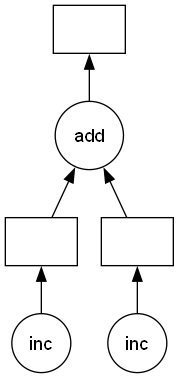

In [6]:
import dask.delayed as delayed
from dask.diagnostics import ProgressBar

def inc(i):
    return i + 1

def add(x, y):
    return x + y

x = delayed(inc)(1)
y = delayed(inc)(2)
z = delayed(add)(x, y)

z.visualize()

### Visualizing More Complex DAGs with Loops and Collections

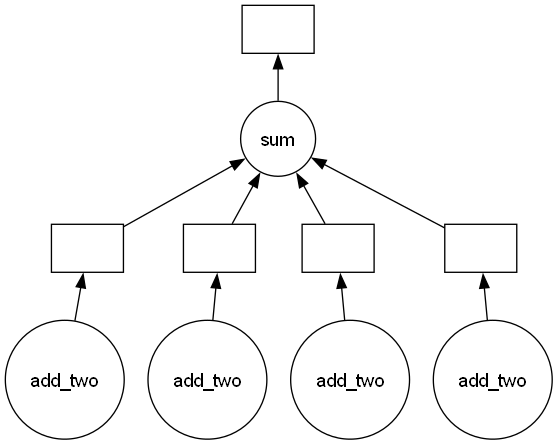

In [7]:
# Listing 2.7
def add_two(x):
    return x + 2

def sum_two_numbers(x,y):
    return x + y

def multiply_four(x):
    return x * 4

data = [1, 5, 8, 10]

step1 = [delayed(add_two)(i) for i in data]
total = delayed(sum)(step1)
total.visualize()

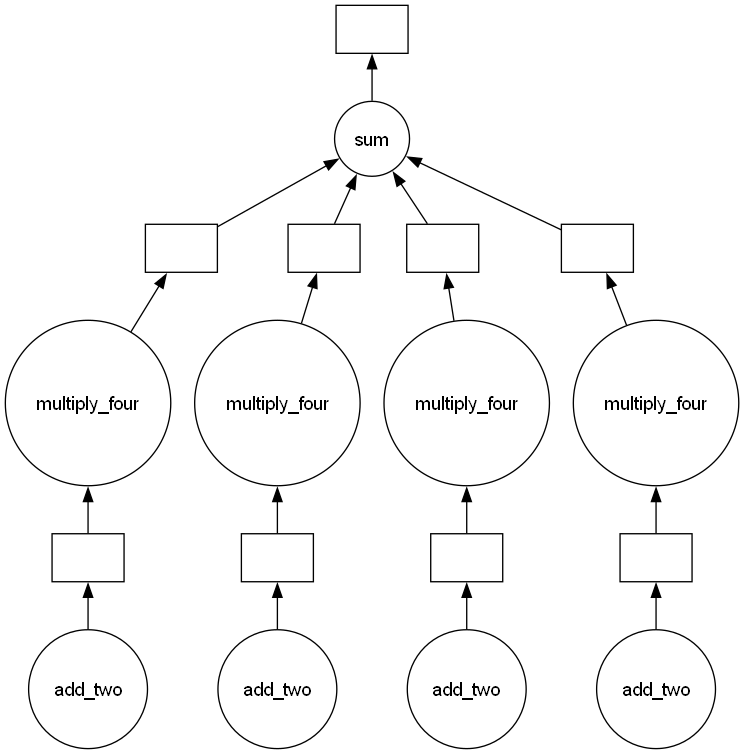

In [8]:
def add_two(x):
    return x + 2

def sum_two_numbers(x,y):
    return x + y

def multiply_four(x):
    return x * 4

data = [1, 5, 8, 10]

step1 = [delayed(add_two)(i) for i in data]
step2 = [delayed(multiply_four)(j) for j in step1]
total = delayed(sum)(step2)
total.visualize()

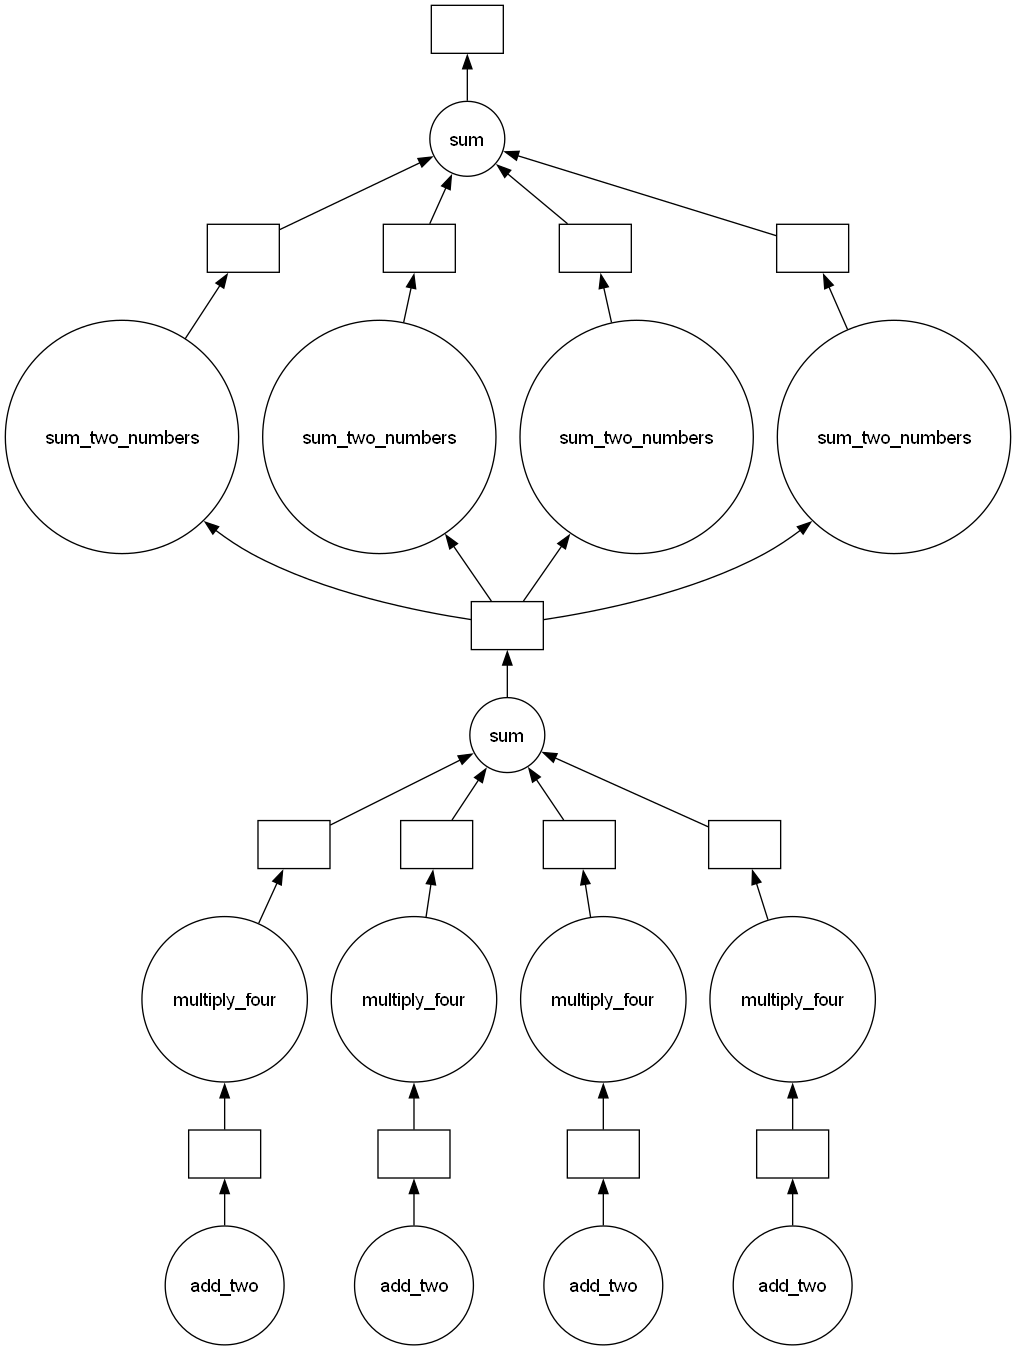

In [9]:
data2 = [delayed(sum_two_numbers)(k, total) for k in data]
total2 = delayed(sum)(data2)
total2.visualize()

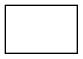

In [10]:
total_persisted = total.persist()
total_persisted.visualize()

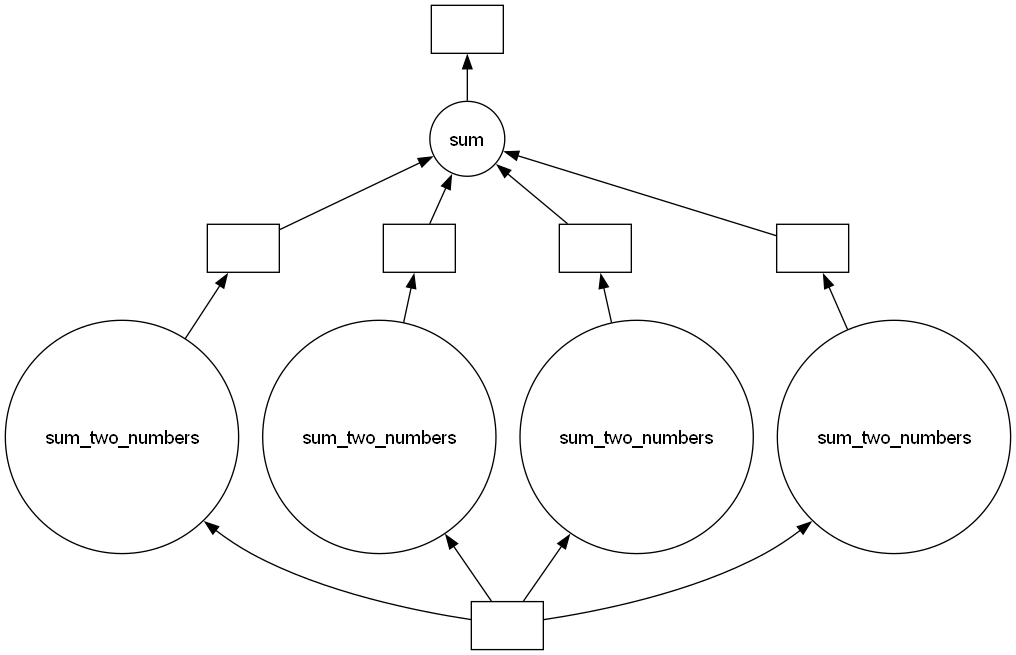

In [11]:
data2 = [delayed(sum_two_numbers)(l, total_persisted) for l in data]
total2 = delayed(sum)(data2)
total2.visualize()

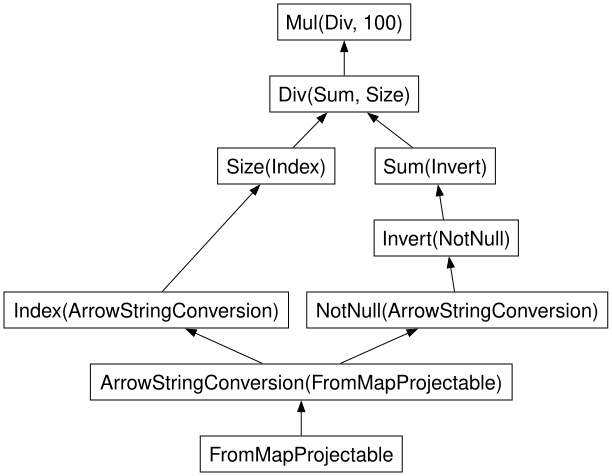

In [12]:
missing_count.visualize()

### Experiment: Pandas vs Dask on the Iris Dataset

Iris is tiny (150 rows), so on its own it fits in memory easily and Dask has no advantage. To see where Dask helps, we replicate Iris into a much larger dataset (about 10.5 million rows) and compare pandas and Dask on the same groupby and filter operations.

In [13]:
import time
import numpy as np
import pandas as pd
import dask.dataframe as dd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
iris['species'] = iris['target'].map(dict(enumerate(load_iris().target_names)))
iris = iris.drop(columns='target')
iris.columns = [c.replace(' (cm)', '').replace(' ', '_') for c in iris.columns]

# Replicate the 150 rows to build a large dataset
big_pd = pd.concat([iris] * 70_000, ignore_index=True)
print(f"Rows: {len(big_pd):,}  |  Memory: {big_pd.memory_usage(deep=True).sum() / 1e6:.0f} MB")

# Same data as a Dask DataFrame split into partitions
big_dd = dd.from_pandas(big_pd, npartitions=8)
big_dd

Rows: 10,500,000  |  Memory: 1190 MB


,sepal_length,sepal_width,petal_length,petal_width,species
npartitions=8,,,,,
0,float64,float64,float64,float64,string
1312500,...,...,...,...,...
...,...,...,...,...,...
9187500,...,...,...,...,...
10499999,...,...,...,...,...


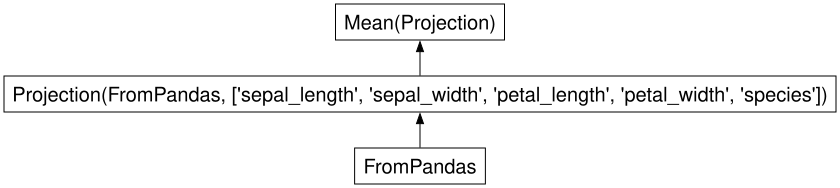

In [14]:
# Lazy: nothing runs yet, Dask only builds the task graph
grouped = big_dd.groupby('species')[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].mean()
grouped.visualize()

In [15]:
# Pandas
t = time.time()
res_pd = big_pd.groupby('species')[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].mean()
t_pd = time.time() - t

# Dask
with ProgressBar():
    t = time.time()
    res_dd = grouped.compute()
    t_dd = time.time() - t

print(f"pandas groupby: {t_pd:.3f}s | dask groupby: {t_dd:.3f}s")
res_dd

[########################################] | 100% Completed | 210.21 ms
pandas groupby: 0.371s | dask groupby: 0.917s


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [16]:
# Filter + aggregate: long petals, average sepal length per species
t = time.time()
f_pd = big_pd[big_pd['petal_length'] > 4].groupby('species')['sepal_length'].agg(['count', 'mean'])
t_pd = time.time() - t

f_task = big_dd[big_dd['petal_length'] > 4].groupby('species')['sepal_length'].agg(['count', 'mean'])
t = time.time()
f_dd = f_task.compute()
t_dd = time.time() - t

print(f"pandas: {t_pd:.3f}s | dask: {t_dd:.3f}s")
f_dd

pandas: 0.380s | dask: 0.928s


,count,mean
species,,
versicolor,2380000,6.147059
virginica,3500000,6.588000


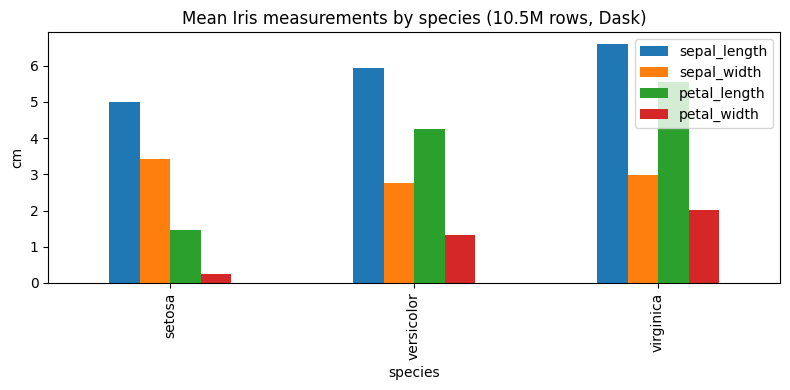

In [17]:
# Plot the Dask result
res_dd.plot(kind='bar', figsize=(8, 4), title='Mean Iris measurements by species (10.5M rows, Dask)')
plt.ylabel('cm')
plt.tight_layout()
plt.show()

**What I noticed:** The Dask result matches pandas exactly, since Iris replicated is still the same distribution. Dask builds a task graph first and only runs it on `.compute()`, and the graph visualization shows the groupby being split across the 8 partitions and then combined. On this dataset, which still fits in memory, pandas is often as fast or faster, because Dask adds scheduling overhead. Dask pays off when the data no longer fits in RAM (like the 2GB parking tickets data above), or when the work is heavy enough to benefit from running partitions in parallel.